# Laboratorio 16 — AdaBoost desde cero

Bagging y el bosque aleatorio construyen sus árboles **en paralelo e independientes**.
AdaBoost los construye **uno tras otro**: cada árbol se ajusta a los mismos datos con
pesos que crecen sobre las observaciones que los anteriores clasificaron mal, y la
predicción es un **voto ponderado**. Este laboratorio implementa ese algoritmo con
`numpy` y un árbol de `scikit-learn` como weak learner.

La pregunta que se responde es una:

> ¿Qué hace AdaBoost con los pesos y con el voto, etapa por etapa, y por qué el voto de
> varios stumps dibuja una frontera que ninguno dibuja solo?

Lo que se escribe son dos funciones: el **ajuste** de AdaBoost, siguiendo el pseudocódigo
de las notas, y la **predicción** por voto ponderado. Los datos son los diez puntos del
ejercicio de las slides, cuyas cifras se calculan a mano en ese ejercicio.

Contra qué se verifica, en orden:

1. Las cifras del ejercicio: los errores ponderados $0{,}30$, $0{,}21$, $0{,}14$ y un voto
   de tres stumps que clasifica bien los diez puntos.
2. `AdaBoostClassifier` de `scikit-learn`, con $50$ etapas: los mismos $\alpha_b$, los
   mismos errores y las mismas predicciones en todo el plano.

Las celdas que contienen `raise NotImplementedError()` deben completarse; el resto es
andamiaje y se ejecuta sin modificar.

## 0. Preparación

In [1]:
from __future__ import annotations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

SEMILLA = 42

plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

AZUL, NARANJA, VIOLETA, GRIS = "#19326E", "#CD742A", "#A3477F", "#8A8A8A"

### Los diez puntos

El conjunto de las slides: diez puntos en el plano, cinco de cada clase, que ningún
corte paralelo a un eje separa. AdaBoost trabaja con $y_i\in\{-1,+1\}$: el voto es el
**signo** de una suma.

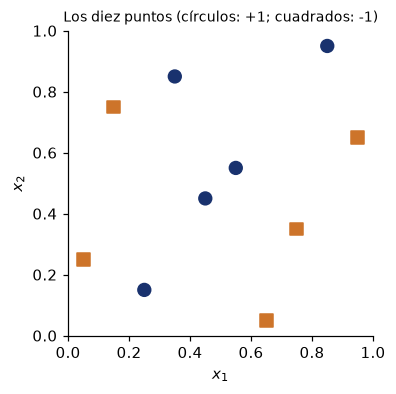

In [2]:
X_diez = np.array([[0.85, 0.95], [0.35, 0.85], [0.55, 0.55], [0.25, 0.15], [0.45, 0.45],
                   [0.75, 0.35], [0.65, 0.05], [0.15, 0.75], [0.05, 0.25], [0.95, 0.65]])
y_diez = np.array([+1, +1, +1, +1, +1, -1, -1, -1, -1, -1])


def dibujar_puntos(ax, tam: float | np.ndarray = 70) -> None:
    """Los diez puntos: circulos para y = +1, cuadrados para y = -1."""
    tam = np.broadcast_to(tam, y_diez.shape)
    for signo, color, marca in [(+1, AZUL, "o"), (-1, NARANJA, "s")]:
        m = y_diez == signo
        ax.scatter(X_diez[m, 0], X_diez[m, 1], s=tam[m], color=color, marker=marca, zorder=3)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")


fig, ax = plt.subplots(figsize=(3.6, 3.6))
dibujar_puntos(ax)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title("Los diez puntos (círculos: +1; cuadrados: -1)", fontsize=9)
plt.show()

## 1. AdaBoost desde cero

El pseudocódigo de las notas (ESL, Algoritmo 10.1, AdaBoost.M1):

```
ADABOOST
Entrada: D = {(x_i, y_i)}, i = 1..n, con y_i en {-1, +1};
         un weak learner FIT(D, w) que acepta pesos por observación;  B
Salida:  los aprendices débiles f_1, ..., f_B y sus pesos alpha_1, ..., alpha_B
1.  w_i <- 1/n para todo i
2.  para b = 1 .. B:
3.      f_b <- FIT(D, w)
4.      err_b <- sum_i w_i · 1[y_i != f_b(x_i)]  /  sum_i w_i
5.      si err_b = 0 o err_b >= 1/2: detener
6.      alpha_b <- log((1 - err_b) / err_b)
7.      w_i <- w_i · exp(alpha_b · 1[y_i != f_b(x_i)])  para todo i
8.      w <- w / sum_i w_i
9.  devolver {f_b}, {alpha_b}
Predicción en x_0:  sign( sum_b alpha_b · f_b(x_0) )
```

El weak learner es un `DecisionTreeClassifier` de profundidad acotada —con profundidad $1$, un *stump*—; los pesos entran
por el argumento `sample_weight` de su `fit`. Lo que se escribe es **el bucle**: las
líneas 1 a 9.

Tres detalles de la línea 5:

- Si $\operatorname{err}_b=0$, el aprendiz clasifica bien todo y $\alpha_b$ sería
  infinito: se **conserva** ese aprendiz con $\alpha_b=1$ y se detiene, porque no queda
  nada que corregir. Es la convención de `scikit-learn`, y la que permite comparar.
- Si $\operatorname{err}_b\ge\tfrac12$, el aprendiz no es mejor que el azar sobre los
  datos ponderados: **se descarta** y se detiene.
- En los dos casos la función devuelve menos de $B$ aprendices.

In [3]:
def adaboost_ajustar(X, y, B, profundidad=1):
    X, y = np.asarray(X), np.asarray(y)
    if len(y) == 0 or not np.isin(y, [-1, 1]).all():
        raise ValueError("y debe contener etiquetas -1 y +1 y no estar vacío")
    w = np.full(len(y), 1.0 / len(y))
    aprendices, alphas, errores = [], [], []
    for _ in range(B):
        f = DecisionTreeClassifier(max_depth=profundidad, random_state=SEMILLA)
        f.fit(X, y, sample_weight=w)
        mal = f.predict(X) != y
        err = float(np.dot(w, mal) / w.sum())
        if err >= 0.5:
            break
        alpha = 1.0 if err == 0 else float(np.log((1 - err) / err))
        aprendices.append(f)
        alphas.append(alpha)
        errores.append(err)
        if err == 0:
            break
        w *= np.exp(alpha * mal)
        w /= w.sum()
    return aprendices, np.array(alphas), np.array(errores)


La predicción es la última línea del pseudocódigo: la suma de los votos de los aprendices débiles,
cada uno multiplicado por su $\alpha_b$, y el signo de esa suma.

In [4]:
def adaboost_predecir(aprendices, alphas, X):
    if len(aprendices) != len(alphas):
        raise ValueError("Debe haber un alpha por aprendiz")
    if not aprendices:
        raise ValueError("No hay aprendices: no se pudo construir el clasificador")
    voto = np.zeros(len(X), dtype=float)
    for f, alpha in zip(aprendices, alphas):
        voto += alpha * f.predict(X)
    return np.where(voto >= 0, 1, -1)


### Verificación sobre los diez puntos

Tres etapas con stumps. Las cifras esperadas son las del ejercicio y de las slides que lo
continúan: $\operatorname{err}_1=0{,}30$ (el primer stump clasifica mal tres puntos),
$\operatorname{err}_2=0{,}21$, $\operatorname{err}_3=0{,}14$, y el voto de los tres
stumps clasifica bien los diez.

In [5]:
# VERIFICACIÓN
stumps_diez, alphas_diez, errores_diez = adaboost_ajustar(X_diez, y_diez, B=3)

assert len(stumps_diez) == 3, "tienen que quedar tres stumps"
assert np.allclose(errores_diez, [3 / 10, 3 / 14, 3 / 22]), f"errores: {errores_diez}"
assert np.allclose(alphas_diez, np.log((1 - errores_diez) / errores_diez))

tabla_diez = pd.DataFrame({
    "err_b": errores_diez,
    "alpha_b": alphas_diez,
    "error del voto de las b primeras": [
        (adaboost_predecir(stumps_diez[:b], alphas_diez[:b], X_diez) != y_diez).mean()
        for b in (1, 2, 3)],
}, index=pd.Index([1, 2, 3], name="b"))
assert tabla_diez.iloc[-1, -1] == 0, "el voto de tres stumps tiene que separar los diez puntos"
print("Verificacion sobre los diez puntos: OK")
tabla_diez.round(4)

Verificacion sobre los diez puntos: OK
    err_b  alpha_b  error del voto de las b primeras
b                                                   
1  0.3000   0.8473                               0.3
2  0.2143   1.2993                               0.3
3  0.1364   1.8458                               0.0


### Para analizar

1. El error de entrenamiento del voto **no baja** de la etapa $1$ a la $2$, aunque el
   segundo stump tiene menor error ponderado que el primero. ¿Qué predice el voto de los
   dos primeros stumps en los puntos donde discrepan, y por qué? (Comparar $\alpha_1$ con
   $\alpha_2$.)
2. Con tres stumps el error llega a $0$. Ningún $\alpha_b$ supera la suma de los otros
   dos: ¿qué significa eso para el signo de la suma, y por qué produce una frontera que
   ningún stump dibuja solo?

**Respuesta:**

1. Donde los dos stumps discrepan, el voto toma la predicción del segundo: alpha₂ = 1,2993 supera a alpha₁ = 0,8473. La suma queda con el signo de f₂. Su error ponderado es menor (0,2143 frente a 0,3000), pero se calcula con otra distribución de pesos; no implica un menor error no ponderado del voto. El error del voto es 0,30 en ambas etapas: cambian las predicciones, pero siguen siendo tres los puntos mal clasificados.
2. Los pesos son 0,8473, 1,2993 y 1,8458. Como cada uno es menor que la suma de los otros dos, cuando dos stumps coinciden su voto conjunto vence al tercero: el signo coincide con la mayoría de los tres. Al combinar cortes sobre distintos ejes, las regiones forman una frontera escalonada, en vez del único corte que puede dibujar un stump. Así se clasifican bien los diez puntos y el error es 0.


### Verificación contra `scikit-learn`

`AdaBoostClassifier` implementa SAMME, la versión multiclase de AdaBoost, que con dos
clases coincide con AdaBoost.M1: el término adicional $\log(K-1)$ de su $\alpha_b$ vale
$0$ para $K=2$. Con $50$ stumps sobre los diez puntos, los $\alpha_b$ y los errores
ponderados tienen que coincidir, y las predicciones también, en una grilla que cubre el
plano.

In [6]:
# VERIFICACIÓN
B_VERIF = 50
aprendices, alphas, errores = adaboost_ajustar(X_diez, y_diez, B=B_VERIF)

referencia = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=B_VERIF,
                                random_state=SEMILLA).fit(X_diez, y_diez)

assert len(alphas) == len(referencia.estimator_weights_), "distinto numero de etapas"
assert np.allclose(alphas, referencia.estimator_weights_), "los alpha_b no coinciden"
assert np.allclose(errores, referencia.estimator_errors_), "los err_b no coinciden"

malla = np.linspace(0, 1, 201)
MX, MY = np.meshgrid(malla, malla)
GRILLA = np.c_[MX.ravel(), MY.ravel()]
assert np.array_equal(adaboost_predecir(aprendices, alphas, GRILLA),
                      referencia.predict(GRILLA)), "las predicciones no coinciden"

print(f"Verificacion contra AdaBoostClassifier: OK ({len(alphas)} etapas, {len(GRILLA)} puntos de la grilla)")

Verificacion contra AdaBoostClassifier: OK (50 etapas, 40401 puntos de la grilla)


## 2. La frontera, etapa por etapa

Con las dos funciones ya verificadas, la celda siguiente dibuja la región que predice el
voto de los $b$ primeros stumps, para $b=1,2,3$ y $b=50$. En los tres primeros paneles,
el área de cada punto es proporcional al peso $w_i^{(b)}$ con que se ajustó el stump $b$,
recalculado con la línea 7 del pseudocódigo a partir de los errores de los anteriores.

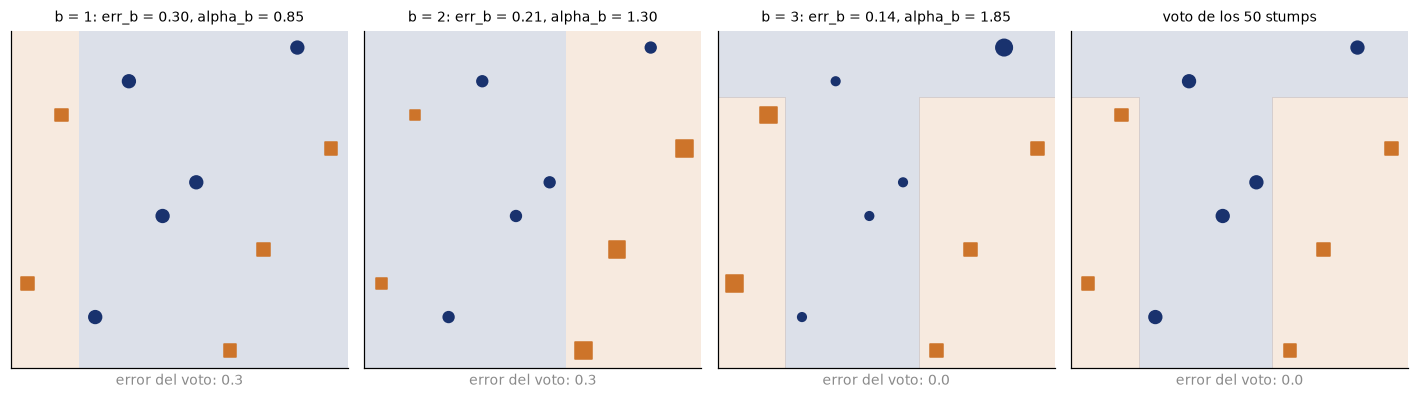

In [7]:
def pesos_por_etapa(aprendices: list, alphas: np.ndarray, X: np.ndarray, y: np.ndarray) -> np.ndarray:
    """Los pesos w^(b) con que se ajusto cada stump: lineas 1, 7 y 8 del pseudocodigo."""
    w = np.full(len(y), 1.0 / len(y))
    pesos = []
    for f, a in zip(aprendices, alphas):
        pesos.append(w)
        w = w * np.exp(a * (f.predict(X) != y))
        w = w / w.sum()
    return np.array(pesos)


W = pesos_por_etapa(aprendices, alphas, X_diez, y_diez)

fig, axs = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, b in zip(axs, [1, 2, 3, len(alphas)]):
    z = adaboost_predecir(aprendices[:b], alphas[:b], GRILLA).reshape(MX.shape)
    ax.contourf(MX, MY, z, levels=[-2, 0, 2], colors=[NARANJA, AZUL], alpha=0.15)
    error_voto = (adaboost_predecir(aprendices[:b], alphas[:b], X_diez) != y_diez).mean()
    if b <= 3:
        dibujar_puntos(ax, 700 * W[b - 1])
        titulo = f"b = {b}: err_b = {errores[b - 1]:.2f}, alpha_b = {alphas[b - 1]:.2f}"
    else:
        dibujar_puntos(ax)
        titulo = f"voto de los {b} stumps"
    ax.set_title(titulo, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlabel(f"error del voto: {error_voto:.1f}", fontsize=9, color=GRIS)
plt.tight_layout()
plt.show()

### Para analizar

1. Del panel $b=1$ al $b=2$, ¿qué puntos crecieron y por qué? ¿Qué parte del peso total
   llevan en la etapa $2$?
2. Entre $b=3$ y $b=50$ el error del voto sigue en $0$. ¿Cambia la frontera? ¿Qué siguen
   haciendo las etapas, si ya no hay errores de entrenamiento que corregir?

**Respuesta:**

1. Crecen los puntos 6, 7, 10, numerados del 1 al 10 en el orden de X_diez: son los tres que el primer stump clasifica mal. Sus pesos pasan de 0,1 a 1/6 cada uno; los siete aciertos quedan con 1/14 cada uno. Los tres errores llevan en total 1/2 del peso de la etapa 2. Se obtiene multiplicando sus pesos por exp(alpha₁) = 7/3 y normalizando por 1,4.
2. En esta ejecución, entre b=3 y b=50 la clasificación de la grilla no cambia en ninguno de los 40.401 puntos; el error de entrenamiento permanece en cero. Esto no es una regla general sobre todas las fronteras de AdaBoost. Las etapas siguen reponderando los errores de cada stump individual, aunque el voto acumulado ya acierte todos los puntos. Por eso cambian los pesos y el valor de la suma ponderada; acertar todas las etiquetas no es el criterio de parada. Solo se detiene si un aprendiz individual tiene error cero o si no mejora el azar.


## Cierre

- **AdaBoost es un bucle de nueve líneas** sobre un árbol que acepta pesos: reponderar
  lo mal clasificado, pesar el voto de cada weak learner por el logaritmo de sus odds de
  acertar, y sumar. Implementado así, coincide con `AdaBoostClassifier` etapa por etapa.
- **Cada stump recibe un problema distinto**: tras reponderar, el último stump tiene
  error ponderado $\tfrac12$ y el siguiente tiene que encontrar otro corte.
- **El voto ponderado de stumps dibuja fronteras que ninguno dibuja**: con tres cortes,
  una escalera que separa los diez puntos.

## Para seguir explorando

Fuera del tiempo de clase, sin evaluación.

- **Un conjunto de datos real.** Aplicar `adaboost_ajustar` con stumps y con árboles de
  profundidad $3$ a un conjunto con interacciones y comparar las curvas de error por
  etapa: una suma de stumps no tiene interacciones.
- **Etiquetas ruidosas.** Invertir la etiqueta de uno de los diez puntos y mirar a dónde
  va el peso después de $50$ etapas.
- **Gradient boosting desde cero.** Con `DecisionTreeRegressor(max_depth=1)`:
  $F_0=\bar y$, residuo $r=y-F$, árbol al residuo, $F\leftarrow F+\eta\hat f$.

In [1]:
from __future__ import annotations
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, make_friedman1
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import mean_squared_error
SEMILLA = 42

def ruta_datos(nombre):
    candidatas = [Path("data") / nombre, Path("../data") / nombre, Path(nombre)]
    ruta = next((p for p in candidatas if p.exists()), None)
    if ruta is None:
        raise FileNotFoundError(f"Falta {nombre}: colocarlo en data/")
    return ruta


In [2]:
def adaboost_ajustar(X, y, B, profundidad=1):
    X, y = np.asarray(X), np.asarray(y)
    if len(y) == 0 or not np.isin(y, [-1, 1]).all():
        raise ValueError("y debe contener etiquetas -1 y +1 y no estar vacío")
    w = np.full(len(y), 1.0 / len(y))
    aprendices, alphas, errores = [], [], []
    for _ in range(B):
        f = DecisionTreeClassifier(max_depth=profundidad, random_state=SEMILLA)
        f.fit(X, y, sample_weight=w)
        mal = f.predict(X) != y
        err = float(np.dot(w, mal) / w.sum())
        if err >= 0.5:
            break
        alpha = 1.0 if err == 0 else float(np.log((1 - err) / err))
        aprendices.append(f)
        alphas.append(alpha)
        errores.append(err)
        if err == 0:
            break
        w *= np.exp(alpha * mal)
        w /= w.sum()
    return aprendices, np.array(alphas), np.array(errores)

def adaboost_predecir(aprendices, alphas, X):
    if len(aprendices) != len(alphas):
        raise ValueError("Debe haber un alpha por aprendiz")
    if not aprendices:
        raise ValueError("No hay aprendices: no se pudo construir el clasificador")
    voto = np.zeros(len(X), dtype=float)
    for f, alpha in zip(aprendices, alphas):
        voto += alpha * f.predict(X)
    return np.where(voto >= 0, 1, -1)


## 1. Un conjunto real: stumps vs árboles de profundidad 3


wdbc: (569, 30) entrenamiento: 426 prueba: 143
             etapa  error_ent  error_prueba
profundidad                                
1              100        0.0         0.021
3              100        0.0         0.021


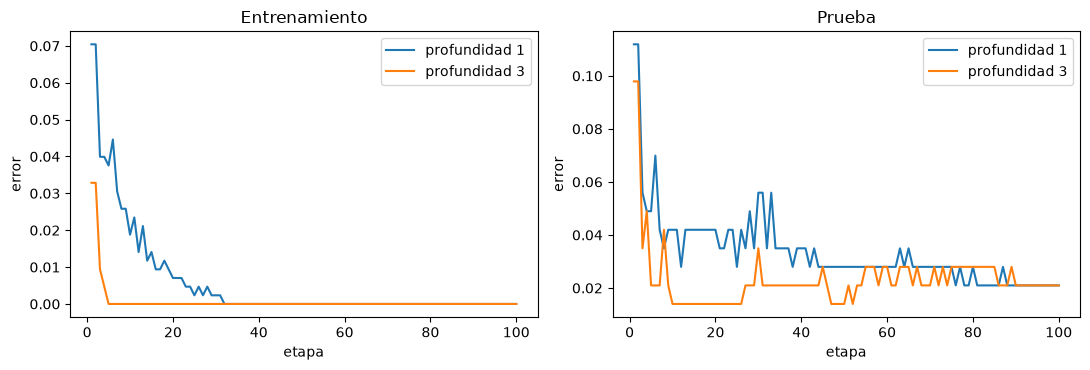

In [3]:
# 1. Datos reales: misma partición y presupuesto para ambas profundidades.
bc = load_breast_cancer()
X_real, y_real = bc.data, np.where(bc.target == 0, 1, -1)
Xe16, Xp16, ye16, yp16 = train_test_split(
    X_real, y_real, test_size=0.25, stratify=y_real, random_state=SEMILLA)
B_REAL = 100
curvas_real, modelos_real = [], {}
for profundidad in [1, 3]:
    fs, aa, ee = adaboost_ajustar(Xe16, ye16, B_REAL, profundidad)
    modelos_real[profundidad] = (fs, aa, ee)
    for b in range(1, len(fs) + 1):
        curvas_real.append({"profundidad": profundidad, "etapa": b,
                            "error_ent": np.mean(adaboost_predecir(fs[:b], aa[:b], Xe16) != ye16),
                            "error_prueba": np.mean(adaboost_predecir(fs[:b], aa[:b], Xp16) != yp16)})
curvas_real = pd.DataFrame(curvas_real)
finales_real = curvas_real.groupby("profundidad").tail(1).set_index("profundidad")
print("wdbc:", X_real.shape, "entrenamiento:", len(ye16), "prueba:", len(yp16))
print(finales_real.round(4).to_string())
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for profundidad, datos in curvas_real.groupby("profundidad"):
    for ax, col, titulo in zip(axs, ["error_ent", "error_prueba"], ["Entrenamiento", "Prueba"]):
        ax.plot(datos.etapa, datos[col], label=f"profundidad {profundidad}")
        ax.set(xlabel="etapa", ylabel="error", title=titulo)
        ax.legend()
plt.tight_layout(); plt.show()


**Análisis:**

Se usó wdbc, un dataset real de 569 observaciones y 30 atributos, con una partición estratificada fija de 426 para entrenamiento y 143 para prueba. Al terminar 100 etapas, los stumps tienen error de entrenamiento 0.0000 y de prueba 0.0210; los árboles de profundidad 3 tienen 0.0000 y 0.0210, respectivamente. El gráfico muestra cómo evolucionan ambos errores, incluyendo posibles oscilaciones del error de clasificación.

Cada stump depende de un solo atributo: una suma de stumps es aditiva en sus puntuaciones y no tiene términos de interacción. La clasificación final sí aplica un umbral a esa suma. Un árbol de profundidad 3 puede condicionar un corte a cortes previos de otros atributos y representar interacciones. Es más flexible, pero una reducción mayor del error de entrenamiento no garantiza una mejora de prueba. Estos resultados de una partición permiten comparar los comportamientos; no prueban que las interacciones sean la única causa de la diferencia. Para elegir profundidad y cantidad de etapas se usaría validación, reservando prueba para la evaluación final.


## 2. Etiquetas ruidosas: invertir una etiqueta de los diez puntos


 punto  y_original  y_ruidosa  peso_final  etiqueta_invertida
     1           1          1      0.1667               False
     9          -1         -1      0.1667               False
     8          -1         -1      0.1667               False
     4           1          1      0.1545               False
     5           1          1      0.1545               False
     6          -1         -1      0.0477               False
     7          -1         -1      0.0477               False
     3           1         -1      0.0477                True
    10          -1         -1      0.0477               False
     2           1          1      0.0000               False
etapas: 50 error con etiquetas ruidosas: 0.0 error con etiquetas originales: 0.1


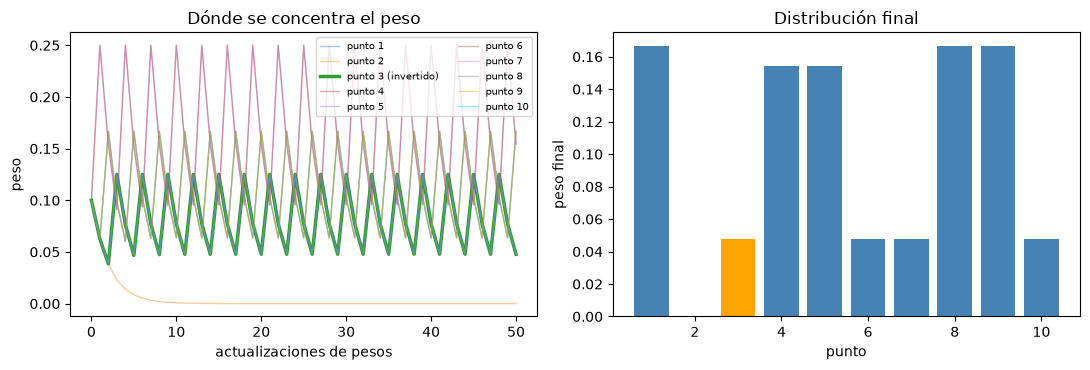

In [4]:
# 2. Invertir exactamente una etiqueta, sin mover ningún punto.
X_ruido = np.array([[0.85, 0.95], [0.35, 0.85], [0.55, 0.55], [0.25, 0.15], [0.45, 0.45],
                    [0.75, 0.35], [0.65, 0.05], [0.15, 0.75], [0.05, 0.25], [0.95, 0.65]])
y_limpio = np.array([1, 1, 1, 1, 1, -1, -1, -1, -1, -1])
INDICE_RUIDO = 2  # tercer punto: (0.55, 0.55)
y_ruido = y_limpio.copy()
y_ruido[INDICE_RUIDO] *= -1
fs_ruido, aa_ruido, ee_ruido = adaboost_ajustar(X_ruido, y_ruido, B=50)
w = np.full(len(y_ruido), 1 / len(y_ruido))
historia_w = [w.copy()]
for f, a, e in zip(fs_ruido, aa_ruido, ee_ruido):
    if e == 0:
        break  # alpha=1 es la convención de parada, no un paso de reponderación
    w *= np.exp(a * (f.predict(X_ruido) != y_ruido))
    w /= w.sum()
    historia_w.append(w.copy())
historia_w = np.array(historia_w)
pesos_finales = pd.DataFrame({"punto": np.arange(1, 11), "y_original": y_limpio,
                             "y_ruidosa": y_ruido, "peso_final": w,
                             "etiqueta_invertida": np.arange(10) == INDICE_RUIDO})
pred_ruido = adaboost_predecir(fs_ruido, aa_ruido, X_ruido)
err_ruidosas = float(np.mean(pred_ruido != y_ruido))
err_originales = float(np.mean(pred_ruido != y_limpio))
print(pesos_finales.sort_values("peso_final", ascending=False).round(4).to_string(index=False))
print("etapas:", len(fs_ruido), "error con etiquetas ruidosas:", err_ruidosas,
      "error con etiquetas originales:", err_originales)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for i in range(10):
    axs[0].plot(historia_w[:, i], alpha=1 if i == INDICE_RUIDO else 0.4,
                lw=2.5 if i == INDICE_RUIDO else 1,
                label=f"punto {i + 1}" + (" (invertido)" if i == INDICE_RUIDO else ""))
axs[0].set(xlabel="actualizaciones de pesos", ylabel="peso", title="Dónde se concentra el peso")
axs[0].legend(fontsize=7, ncol=2)
axs[1].bar(pesos_finales.punto, pesos_finales.peso_final,
           color=["orange" if i == INDICE_RUIDO else "steelblue" for i in range(10)])
axs[1].set(xlabel="punto", ylabel="peso final", title="Distribución final")
plt.tight_layout(); plt.show()


**Análisis:**

Se invirtió la etiqueta del punto 3, (0,55; 0,55), de +1 a -1. Después de 50 etapas, su peso es 0.0477, frente al peso inicial 0,1000. Los tres puntos con más peso al final son 1, 9, 8, con pesos 0.1667, 0.1667, 0.1667. La historia permite ver cómo el foco cambia entre ejemplos difíciles; el peso no tiene por qué crecer de forma monótona ni concentrarse exclusivamente en la etiqueta invertida.

El voto tiene error 0.0000 respecto de las etiquetas ruidosas y 0.1000 respecto de las originales. AdaBoost no sabe que una etiqueta fue modificada: aumenta el peso cuando el stump actual se equivoca, aunque corregir ese ejemplo suponga aprender ruido. Un ejemplo con etiqueta invertida puede ser ajustable; no tiene que quedar mal clasificado ni acumular todo el peso. Por eso este experimento evidencia sensibilidad al ruido, pero no una detección automática de etiquetas erróneas. Detener antes o regularizar se decidiría con validación.


## 3. Gradient boosting desde cero


F0: 14.0463 eta: 0.1
 etapa  mse_ent  mse_prueba
     0  24.7361     28.2467
    50   6.7113      9.6489
   100   3.7416      5.5873
   150   2.7781      4.2743


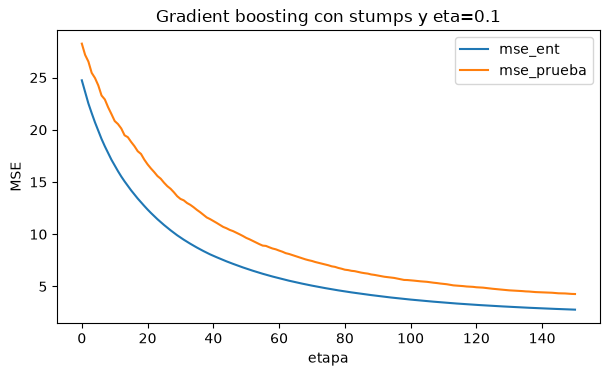

In [5]:
# 3. Gradient boosting de regresión desde cero, con pérdida cuadrática.
def gradient_boosting_ajustar(X, y, B=150, eta=0.1):
    inicial = float(np.mean(y))
    F = np.full(len(y), inicial)
    arboles = []
    for _ in range(B):
        residuo = y - F  # gradiente negativo de 1/2 * (y-F)^2
        f = DecisionTreeRegressor(max_depth=1, random_state=SEMILLA)
        f.fit(X, residuo)
        F += eta * f.predict(X)
        arboles.append(f)
    return inicial, arboles


def gradient_boosting_predecir(inicial, arboles, X, eta=0.1):
    F = np.full(len(X), inicial, dtype=float)
    for f in arboles:
        F += eta * f.predict(X)
    return F


X_reg, y_reg = make_friedman1(n_samples=600, n_features=5, noise=1.0, random_state=SEMILLA)
Xer, Xpr, yer, ypr = train_test_split(X_reg, y_reg, test_size=0.25, random_state=SEMILLA)
ETA = 0.1
F0, arboles_grad = gradient_boosting_ajustar(Xer, yer, B=150, eta=ETA)
Fe, Fp = np.full(len(yer), F0), np.full(len(ypr), F0)
curva_grad = [{"etapa": 0, "mse_ent": mean_squared_error(yer, Fe),
               "mse_prueba": mean_squared_error(ypr, Fp)}]
for b, f in enumerate(arboles_grad, start=1):
    Fe += ETA * f.predict(Xer)
    Fp += ETA * f.predict(Xpr)
    curva_grad.append({"etapa": b, "mse_ent": mean_squared_error(yer, Fe),
                       "mse_prueba": mean_squared_error(ypr, Fp)})
curva_grad = pd.DataFrame(curva_grad)
print("F0:", round(F0, 4), "eta:", ETA)
print(curva_grad.iloc[[0, 50, 100, 150]].round(4).to_string(index=False))
curva_grad.plot(x="etapa", y=["mse_ent", "mse_prueba"], figsize=(7, 3.8))
plt.ylabel("MSE"); plt.title("Gradient boosting con stumps y eta=0.1"); plt.show()


**Análisis:**

Para pérdida cuadrática se inicia con F₀=media(y)=14.0463, se ajusta un stump de regresión al residuo y-F y se suma eta·f, con eta=0,1. En Friedman1 (600 observaciones, cinco atributos y ruido de desvío 1), el MSE pasa de 24.7361 a 2.7781 en entrenamiento y de 28.2467 a 4.2743 en prueba después de 150 etapas.

AdaBoost modifica pesos de observaciones para clasificar; aquí se mantiene el conjunto de atributos y se cambia el objetivo que cada árbol aprende: el residuo, que es el gradiente negativo de la pérdida ½(y-F)². Eta controla el tamaño de cada actualización. Un eta menor suele requerir más etapas; no garantiza por sí solo mejor generalización. Friedman1 incluye la interacción sin(pi·x₁·x₂), que una suma de stumps no representa como un término de interacción: por eso todavía puede quedar error estructural, además del ruido. Árboles más profundos podrían capturar esa interacción, a costa de mayor flexibilidad.
